# 13. Mobility data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/13_mobility.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/13_mobility.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You put GPS traces and sensors on the driving network of Monaco with `duckosm.mobility`, count the traces on each
edge, and keep your data after a rebuild. The GPS traces in this notebook are made up from known routes.

| Call | What it gives |
|---|---|
| `match()` | the edges that each GPS trace drove (map matching), and the edge of each point |
| `snap()` | the nearest edge of each point, for sensors and addresses |
| `aggregate()`, `join()` | counts for each edge and hour, and your data on the edges |
| `edge_id_map()` | the old edge ids on the edges of a new build |

The map matching is the hidden Markov model of Newson and Krumm (2009), solved with the Viterbi algorithm, as in
leuvenmapmatching. See [duckosm.mobility](../reference/sdk/mobility.md).

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook
    %pip install -q "duckosm[analysis,viz]"
    import duckosm         # the SDK
from duckosm import mobility as mob    # the module of this notebook
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


In [2]:
net = duckosm.network("Monaco", modes=["driving"])    # get and build the driving network of Monaco
drive = net.driving                                   # the driving mode
drive                                                 # the card

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## Make GPS traces

Two drives, there and back: a point every 15 m along a route, 4 m off the road at random, with a time. A real GPS
file has the same columns: `trace_id`, `x` (lon), `y` (lat), `time`.

In [3]:
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely.ops import linemerge

def gps(route, trace_id, seed):                                        # made-up GPS points along a route
    roads = net.edges(crs="utm").set_index("edge_id").loc[route["edges"]]    # the edges of the route, in metres
    line = linemerge(list(roads.geometry))                             # one line
    rng = np.random.default_rng(seed)                                  # noise that does not change
    d = np.arange(0, line.length, 15.0)                                # a point every 15 m
    xy = np.array([line.interpolate(m).coords[0] for m in d]) + rng.normal(0, 4, (len(d), 2))    # 4 m off the road
    p = gpd.GeoSeries(gpd.points_from_xy(xy[:, 0], xy[:, 1]), crs=roads.crs).to_crs(4326)    # back to lon, lat
    return pd.DataFrame({"trace_id": trace_id, "x": p.x, "y": p.y,
                         "time": pd.Timestamp("2026-11-20 08:00") + pd.to_timedelta(d / 8, "s")})    # 8 m/s

A, B = (7.4155, 43.7285), (7.4335, 43.7468)                            # two points in Monaco
there, back = drive.route(A, B), drive.route(B, A)                     # the true routes
traces = pd.concat([gps(there, "there", 1), gps(back, "back", 2)], ignore_index=True)    # the GPS file
traces.head()                                                          # the first points

,trace_id,x,y,time
0,there,7.415578,43.728611,2026-11-20 08:00:00.000
1,there,7.415434,43.728618,2026-11-20 08:00:01.875
2,there,7.415362,43.728789,2026-11-20 08:00:03.750
3,there,7.415353,43.728919,2026-11-20 08:00:05.625
4,there,7.415527,43.729007,2026-11-20 08:00:07.500


## Map matching: `match()`

`m.points`: each GPS point with its edge. `m.edges`: the route of each trace, edge by edge. Both drives use the two-way
roads in opposite directions, so they get different edges. With 4 m of GPS noise, a point near a junction can add the
edge before or after the route, or a short road next to it.

In [4]:
m = mob.match(drive, traces)                                          # map matching
for name, true in [("there", there), ("back", back)]:                     # each drive
    got = m.edges[m.edges.trace_id == name].edge_id                       # its matched edges
    print(f"{name}: {got.isin(true['edges']).sum()} of {len(true['edges'])} route edges found, {(~got.isin(true['edges'])).sum()} other")
m.points[["trace_id", "time", "edge_id", "fraction", "distance_m"]].head()          # the points on the edges

there: 74 of 75 route edges found, 5 other
back: 64 of 64 route edges found, 2 other


,trace_id,time,edge_id,fraction,distance_m
0,back,2026-11-20 08:00:00.000,9164240563030343962,1.000000,2.224033
1,back,2026-11-20 08:00:01.875,5478627982403126609,1.000000,8.540619
2,back,2026-11-20 08:00:03.750,5789221358051408561,0.302176,3.399100
3,back,2026-11-20 08:00:05.625,5751627512069328654,0.070886,2.802146
4,back,2026-11-20 08:00:07.500,5751627512069328654,0.603390,2.431693


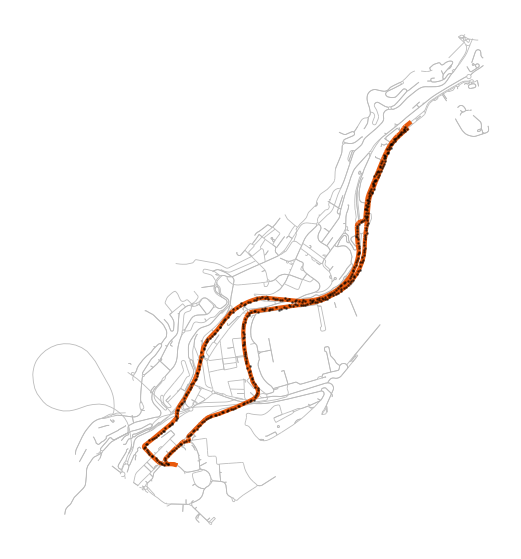

In [5]:
import matplotlib.pyplot as plt

ax = plt.subplots(figsize=(7, 7))[1]                                       # a new picture
net.plot(highlight=m.edges.edge_id, ax=ax)                                 # the matched edges in orange
ax.scatter(traces.x, traces.y, s=1, color="black", alpha=0.5, zorder=3); plt.show()    # the GPS points

## Sensors: `snap()`

A sensor, an address or a shop is one point with no route. `snap` gives its nearest edge and the place on it.

In [6]:
sensors = pd.DataFrame({"sensor": ["s1", "s2", "s3"], "x": [7.4206, 7.4262, 7.4301], "y": [43.7316, 43.7397, 43.7427]})
mob.snap(drive, sensors, radius_m=30)                                      # edge_id, fraction, distance_m, snap_x, snap_y

,sensor,x,y,edge_id,fraction,distance_m,snap_x,snap_y
0,s1,7.4206,43.7316,3913596625020233819,0.918641,6.247255,7.420571,43.731652
1,s2,7.4262,43.7397,1681206748141307799,0.517687,14.168264,7.426373,43.739722
2,s3,7.4301,43.7427,1155660829073038487,0.754625,10.588955,7.430146,43.742789


## Counts per edge and hour: `aggregate()`, `join()`

The count of GPS points on each edge in each hour; then the counts on the map.

                 edge_id                   name  count
43   3487789174266503140  Boulevard du Larvotto     21
112  8691687783733863412         Tunnel Dorsale     17
49   3913596625020233819   Tunnel Rocher Palais     14


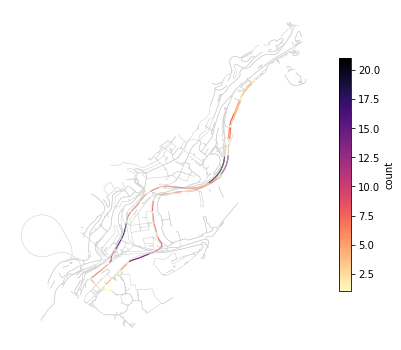

In [7]:
counts = mob.aggregate(drive, m.points, time="hour")                     # edge_id, time, count
by_edge = counts.groupby("edge_id")["count"].sum()                         # the points on each edge
print(mob.join(drive, by_edge)[["edge_id", "name", "count"]].nlargest(3, "count"))    # your data on the edges
net.plot(color_by=by_edge, cmap="magma_r")                                 # the map, colored by the count

## After a rebuild: `edge_id_map()`

The ids stay when a road does not change. Here a fix removes the dead-end street 778494662, as an OSM update can: its
T junction goes, so the road that it met is one edge in each direction, with a new id. `edge_id_map` puts the old ids
on the new edges, so your data stays.

In [8]:
open("data/fix.yaml", "w").write("overrides:\n  - osm_id: 778494662\n    remove: true\n")    # the fix: remove the street
new = duckosm.network("Monaco", modes=["driving"], fixes="data/fix.yaml", name="monaco_fixed")    # build again with it
ids = mob.edge_id_map(drive, new.driving)                                # old edge_id -> new edge_id, share
ids[ids.old_edge_id != ids.new_edge_id]                                  # the edges that changed

cut with the fixes: 34794 nodes, 5692 ways, 343 relations

Output: data/monaco_fixed.duckdb

,old_edge_id,new_edge_id,share
349,1135803928808390220,4352433216998100260,1.0
1129,3640886082708460898,4352433216998100260,1.0
1411,4481486712828221748,105595499196454544,1.0
1414,4495873536865053102,105595499196454544,1.0


In [9]:
moved = counts.merge(ids, left_on="edge_id", right_on="old_edge_id")     # the counts on the new edges
moved["count"] = moved["count"] * moved.share                            # a split edge shares its count
print(counts["count"].sum(), "points before,", round(moved["count"].sum(), 1), "after")    # no count is lost

396 points before, 396.0 after
